In [ ]:
!pip install -q ultralytics transformers
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/lane_work
!cp /content/drive/MyDrive/driving-perception/lane_frames.zip /content/lane_work/
!unzip -q -o /content/lane_work/lane_frames.zip -d /content/lane_work/
!ls /content/drive/MyDrive/driving-perception/runs/improved_yolo11s/weights

Mounted at /content/drive
best.pt  last.pt


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


preprocessor_config.json:   0%|          | 0.00/382 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/9.88k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  490MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/414 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  490MB            

model.safetensors: downloading bytes:           |  0.00B            

{
  "frames": 20,
  "frames_with_3plus_objects": 0,
  "mean_spearman": null,
  "median_spearman": null,
  "depth_model": "Intel/dpt-hybrid-midas (zero-shot, relative depth)",
  "note": "Relative distance only, no metres: the camera is uncalibrated. Spearman compares depth ordering with a flat-road geometric cue (lower box bottom = closer). Indicative only, small sample."
}


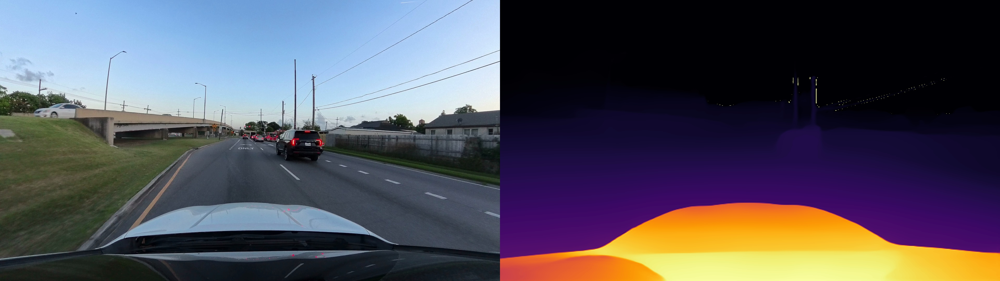

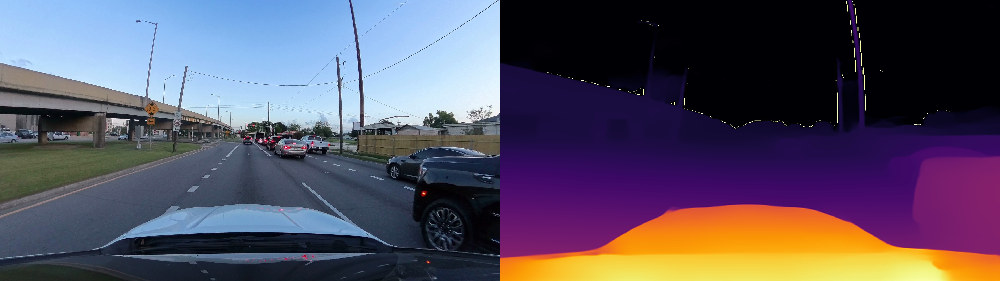

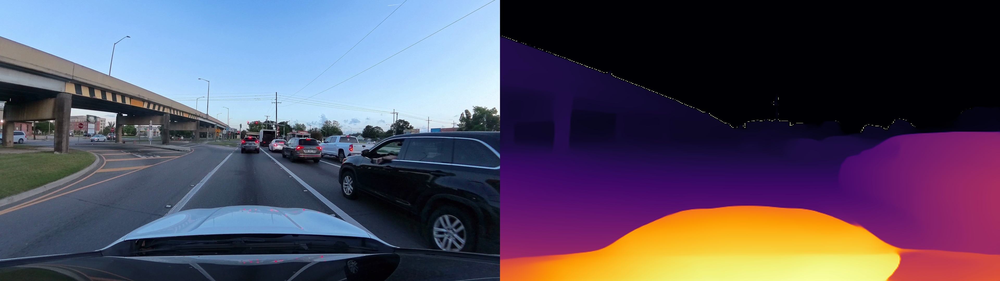

In [ ]:
import glob, os, json
import numpy as np, cv2, torch
from PIL import Image
from scipy.stats import spearmanr
from ultralytics import YOLO
from transformers import DPTImageProcessor, DPTForDepthEstimation

FRAMES = "/content/lane_work/results/lanes/frames"
OUT = "/content/drive/MyDrive/driving-perception/depth_distance"
WEIGHTS = "/content/drive/MyDrive/driving-perception/runs/improved_yolo11s/weights/best.pt"
os.makedirs(OUT, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"

detector = YOLO(WEIGHTS)
proc = DPTImageProcessor.from_pretrained("Intel/dpt-hybrid-midas")
depth_model = DPTForDepthEstimation.from_pretrained("Intel/dpt-hybrid-midas").to(device).eval()


@torch.no_grad()
def depth_map(bgr):
  """Relative inverse depth: bigger number = closer. Scale is arbitrary (not metres)."""
  rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
  inputs = proc(images=Image.fromarray(rgb), return_tensors="pt").to(device)
  pred = depth_model(**inputs).predicted_depth
  pred = torch.nn.functional.interpolate(
      pred.unsqueeze(1), size=bgr.shape[:2], mode="bicubic", align_corners=False)
  return pred.squeeze().cpu().numpy()

def bucket(score):
  # arbitrary display thresholds on a 0-1 relative scale, NOT metres
  return "NEAR" if score >= 0.6 else ("MID" if score >= 0.3 else "FAR")

rows, corrs = [], []
for orig_path in sorted(glob.glob(f"{FRAMES}/*_original.jpg")):
  stem = os.path.basename(orig_path).replace("_original.jpg", "")
  img = cv2.imread(orig_path)
  if img is None:
    print("skipping", stem)
    continue

  d = depth_map(img)
  ref = float(np.percentile(d[: int(0.70 * d.shape[0])], 95))
  res = detector.predict(img, conf=0.10, imgsz=1280, verbose=False)[0]
  overlay = img.copy()
  scores, bottoms = [], []

  for (x1, y1, x2, y2), c in zip(res.boxes.xyxy.cpu().numpy(), res.boxes.cls.int().cpu().numpy()):
    x1, y1, x2, y2 = int(x1), int(y1), int(x2), int(y2)
    lower = d[(y1 + y2) // 2:y2, x1:x2]  # lower half of the box, where it meets the road
    if lower.size == 0:
      continue
      score = float(np.clip(np.median(lower) / ref, 0, 1.5))
      scores.append(score)
      bottoms.append(y2)
      label = f"{detector.names[int(c)]} {bucket(score)}"
      cv2.rectangle(overlay, (x1, y1), (x2, y2), (0, 255, 0), 3)
      cv2.putText(overlay, label, (x1, max(y1 - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)

  rho = None
  if len(scores) >= 3:
    r = spearmanr(scores, bottoms).correlation
    rho = None if np.isnan(r) else round(float(r), 2)
    if rho is not None:
      corrs.append(rho)
  rows.append({"frame": stem, "objects": len(scores), "spearman_depth_vs_box_bottom": rho})

  dn = (255 * d / d.max()).astype(np.uint8)
  depth_vis = cv2.applyColorMap(dn, cv2.COLORMAP_INFERNO)
  panel = cv2.resize(np.hstack([overlay, depth_vis]), None, fx=0.5, fy=0.5)
  cv2.imwrite(f"{OUT}/{stem}_depth.jpg", panel)

summary = {
    "frames": len(rows),
    "frames_with_3plus_objects": len(corrs),
    "mean_spearman": round(float(np.mean(corrs)), 2) if corrs else None,
    "median_spearman": round(float(np.median(corrs)), 2) if corrs else None,
    "depth_model": "Intel/dpt-hybrid-midas (zero-shot, relative depth)",
    "note": ("Relative distance only, no metres: the camera is uncalibrated. Spearman compares "
              "depth ordering with a flat-road geometric cue (lower box bottom = closer). "
              "Indicative only, small sample.")
}
with open(f"{OUT}/depth_summary.json", "w") as f:
  json.dump({"summary": summary, "frames": rows}, f, indent=2)
print(json.dumps(summary, indent=2))
from google.colab.patches import cv2_imshow
for p in sorted(glob.glob(f"{OUT}/*_depth.jpg"))[:3]:
  cv2_imshow(cv2.imread(p))

In [ ]:
import glob, cv2
from ultralytics import YOLO

FRAMES = "/content/lane_work/results/lanes/frames"
WEIGHTS = "/content/drive/MyDrive/driving-perception/runs/improved_yolo11s/weights/best.pt"
det = YOLO(WEIGHTS)
paths = sorted(glob.glob(FRAMES + "/*_original.jpg"))
print(len(paths), "frames; classes:", det.names)
for imgsz in (640, 960, 1280):
  for conf in (0.25, 0.10):
    counts = [len(det.predict(cv2.imread(p), conf=conf, imgsz=imgsz, verbose=False)[0].boxes) for p in paths]
    print(f"imgsz={imgsz} conf={conf}: total boxes={sum(counts)}, frames with at least 1 box={sum(c > 0 for c in counts)}/{len(paths)}")

20 frames; classes: {0: 'vehicle', 1: 'pedestrian', 2: 'cyclist'}
imgsz=640 conf=0.25: total boxes=91, frames with at least 1 box=20/20
imgsz=640 conf=0.1: total boxes=108, frames with at least 1 box=20/20
imgsz=960 conf=0.25: total boxes=116, frames with at least 1 box=20/20
imgsz=960 conf=0.1: total boxes=135, frames with at least 1 box=20/20
imgsz=1280 conf=0.25: total boxes=129, frames with at least 1 box=20/20
imgsz=1280 conf=0.1: total boxes=169, frames with at least 1 box=20/20


20 frames; classes: {0: 'vehicle', 1: 'pedestrian', 2: 'cyclist'}
imgsz=640 conf=0.25: total boxes=91, frames with a box=20/20
imgsz=640 conf=0.1: total boxes=108, frames with a box=20/20
imgsz=640 conf=0.05: total boxes=127, frames with a box=20/20
imgsz=960 conf=0.25: total boxes=116, frames with a box=20/20
imgsz=960 conf=0.1: total boxes=135, frames with a box=20/20
imgsz=960 conf=0.05: total boxes=158, frames with a box=20/20
imgsz=1280 conf=0.25: total boxes=129, frames with a box=20/20
imgsz=1280 conf=0.1: total boxes=169, frames with a box=20/20
imgsz=1280 conf=0.05: total boxes=198, frames with a box=20/20


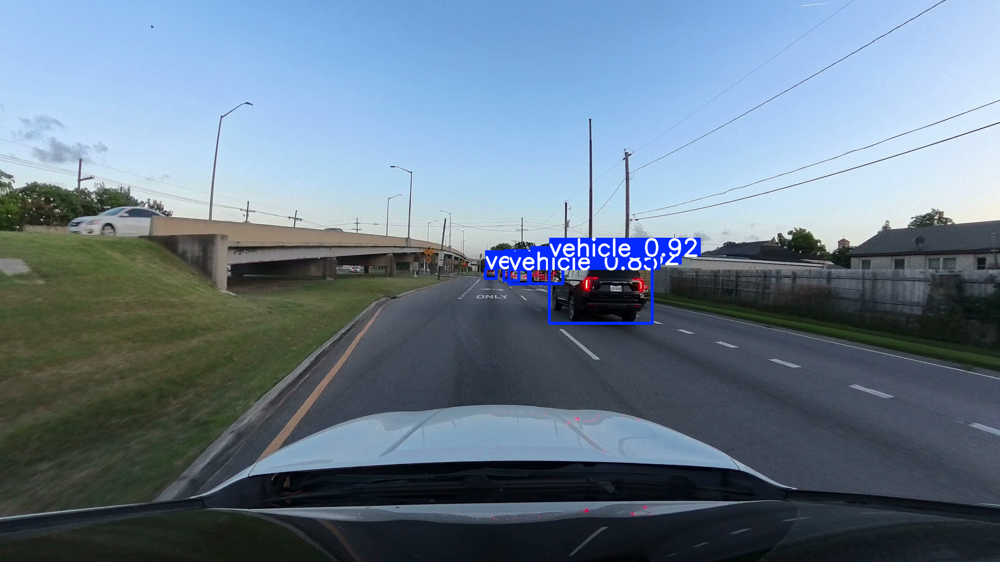

In [ ]:
import glob, cv2
from ultralytics import YOLO
from google.colab.patches import cv2_imshow

FRAMES = "/content/lane_work/results/lanes/frames"
WEIGHTS = "/content/drive/MyDrive/driving-perception/runs/improved_yolo11s/weights/best.pt"
det = YOLO(WEIGHTS)
paths = sorted(glob.glob(FRAMES + "/*_original.jpg"))
print(len(paths), "frames; classes:", det.names)
for imgsz in (640, 960, 1280):
  for conf in (0.25, 0.10, 0.05):
    counts = [len(det.predict(cv2.imread(p), conf=conf, imgsz=imgsz, verbose=False)[0].boxes) for p in paths]
    print(f"imgsz={imgsz} conf={conf}: total boxes={sum(counts)}, frames with a box={sum(c > 0 for c in counts)}/{len(paths)}")
r = det.predict(cv2.imread(paths[0]), conf=0.05, imgsz=1280, verbose=False)[0]
cv2_imshow(cv2.resize(r.plot(), None, fx=0.5, fy=0.5))

Loading weights:   0%|          | 0/414 [00:00<?, ?it/s]

{
  "frames": 20,
  "total_objects": 129,
  "frames_with_3plus_objects": 20,
  "mean_spearman": 0.92,
  "median_spearman": 0.96,
  "detector_settings": {
    "conf": 0.25,
    "imgsz": 1280
  },
  "depth_model": "Intel/dpt-hybrid-midas (zero-shot, relative depth)",
  "note": "Relative distance only, no metres: the camera is uncalibrated. Spearman compares depth ordering with a flat-road geometric cue (lower box bottom = closer). Indicative only, small sample."
}


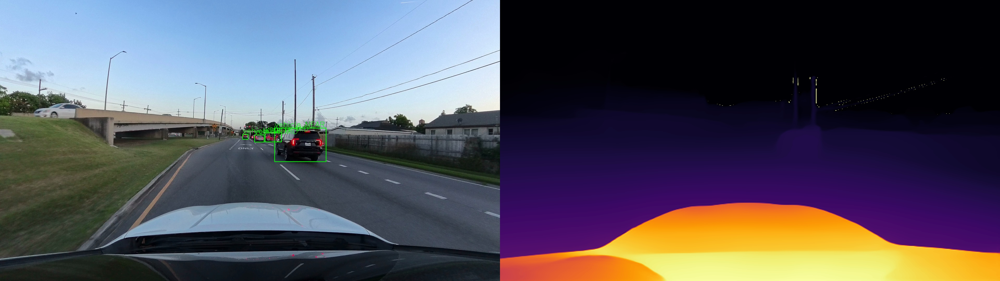

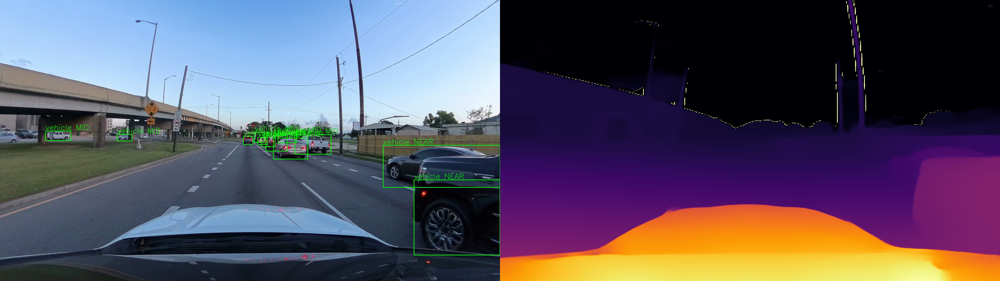

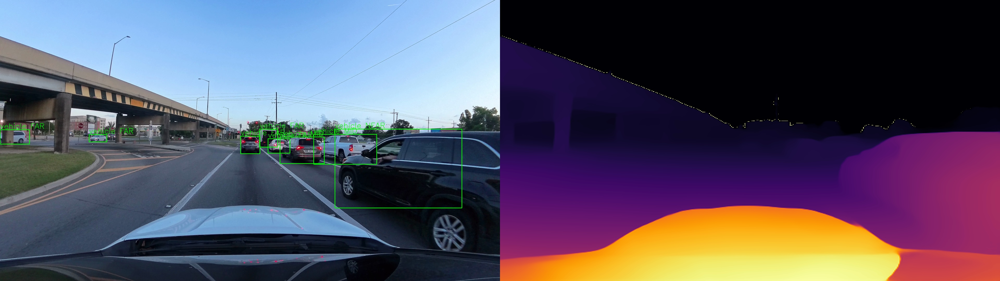

In [ ]:
import glob, os, json
import numpy as np, cv2, torch
from PIL import Image
from scipy.stats import spearmanr
from ultralytics import YOLO
from transformers import DPTImageProcessor, DPTForDepthEstimation

FRAMES = "/content/lane_work/results/lanes/frames"
OUT = "/content/drive/MyDrive/driving-perception/depth_distance"
WEIGHTS = "/content/drive/MyDrive/driving-perception/runs/improved_yolo11s/weights/best.pt"
CONF, IMGSZ = 0.25, 1280
os.makedirs(OUT, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"

detector = YOLO(WEIGHTS)
proc = DPTImageProcessor.from_pretrained("Intel/dpt-hybrid-midas")
depth_model = DPTForDepthEstimation.from_pretrained("Intel/dpt-hybrid-midas").to(device).eval()


@torch.no_grad()
def depth_map(bgr):
  """Relative inverse depth: bigger number = closer. Scale is arbitrary (not metres)."""
  rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
  inputs = proc(images=Image.fromarray(rgb), return_tensors="pt").to(device)
  pred = depth_model(**inputs).predicted_depth
  pred = torch.nn.functional.interpolate(
      pred.unsqueeze(1), size=bgr.shape[:2], mode="bicubic", align_corners=False)
  return pred.squeeze().cpu().numpy()

def bucket(score):
  # arbitrary display thresholds on a relative scale, NOT metres
  return "NEAR" if score >= 0.6 else ("MID" if score >= 0.3 else "FAR")

rows, corrs, total_objects = [], [], 0
for orig_path in sorted(glob.glob(f"{FRAMES}/*_original.jpg")):
  stem = os.path.basename(orig_path).replace("_original.jpg", "")
  img = cv2.imread(orig_path)
  if img is None:
    print("skipping", stem)
    continue

  d = depth_map(img)
  ref = float(np.percentile(d[: int(0.70 * d.shape[0])], 95))  # ignore the hood (bottom 30%)
  res = detector.predict(img, conf=CONF, imgsz=IMGSZ, verbose=False)[0]
  overlay = img.copy()
  fs = max(0.6, img.shape[1] / 2000)
  scores, bottoms = [], []
  for (x1, y1, x2, y2), c in zip(res.boxes.xyxy.cpu().numpy(), res.boxes.cls.int().cpu().numpy()):
    x1, y1, x2, y2 = int(x1), int(y1), int(x2), int(y2)
    lower = d[(y1 + y2) // 2:y2, x1:x2]  # lower half of the box, where it meets the road
    if lower.size == 0:
      continue
    score = float(np.clip(np.median(lower) / ref, 0, 1.5))
    scores.append(score)
    bottoms.append(y2)
    label = f"{detector.names[int(c)]} {bucket(score)}"
    cv2.rectangle(overlay, (x1, y1), (x2, y2), (0, 255, 0), 3)
    cv2.putText(overlay, label, (x1, max(y1 - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX, fs, (0, 255, 0), 2)

  total_objects += len(scores)
  rho = None
  if len(scores) >= 3:
    r = spearmanr(scores, bottoms).correlation
    rho = None if np.isnan(r) else round(float(r), 2)
    if rho is not None:
      corrs.append(rho)
  rows.append({"frame": stem, "objects": len(scores), "spearman_depth_vs_box_bottom": rho})
  dn = (255 * d / d.max()).astype(np.uint8)
  depth_vis = cv2.applyColorMap(dn, cv2.COLORMAP_INFERNO)
  panel = cv2.resize(np.hstack([overlay, depth_vis]), None, fx=0.5, fy=0.5)
  cv2.imwrite(f"{OUT}/{stem}_depth.jpg", panel)
summary = {
    "frames": len(rows),
    "total_objects": total_objects,
    "frames_with_3plus_objects": len(corrs),
    "mean_spearman": round(float(np.mean(corrs)), 2) if corrs else None,
    "median_spearman": round(float(np.median(corrs)), 2) if corrs else None,
    "detector_settings": {"conf": CONF, "imgsz": IMGSZ},
    "depth_model": "Intel/dpt-hybrid-midas (zero-shot, relative depth)",
    "note": ("Relative distance only, no metres: the camera is uncalibrated. Spearman compares "
             "depth ordering with a flat-road geometric cue (lower box bottom = closer). "
             "Indicative only, small sample."),
}
with open(f"{OUT}/depth_summary.json", "w") as f:
  json.dump({"summary": summary, "frames": rows}, f, indent=2)
print(json.dumps(summary, indent=2))

from google.colab.patches import cv2_imshow
for p in sorted(glob.glob(f"{OUT}/*_depth.jpg"))[:3]:
  cv2_imshow(cv2.imread(p))